In [48]:
from src.dataset_overview import load_data,data_understanding
import pandas as pd
from src.data_preprocessing import (
    analyze_outliers,analyze_duplicates,
    analyze_missing_values,analyze_inconsistency,
    convert_data_types,handle_duplicates,handle_missing_values,handle_outliers
)
from src.exploratory_data_analysis import separate_feature_types


In [49]:
# path = "../data/raw/Cardiovascular_Disease_Dataset.csv"
# target = "target"

# path = "../data/raw/dataset_regresi_dummy_110.csv"
# target = "harga_rumah_juta" 

# df_sample = load_data(file_path=path)
# df_sample.head()

data_kotor = {
        "ID_Pelanggan": [101, 102, 103, 103, 104, 105, 106, 10009],
        "Kota": ["Jakarta", "jakarta ", "BANDUNG", "BANDUNG", "Surabaya", "surabaya", None, "Medan"],
        "Usia": [25, 30, 28, 28, -5, 42, 150, 35],          # Ada nilai negatif (-5) dan outlier (150)
        "Pendapatan": [5000, 6200, 5800, 5800, None, 7100, 95000, 6000], # Ada missing value & outlier (95000)
        "Status_Aktif": ["Ya", "ya", "Tidak", "Tidak", "YA ", None, "Tidak", "N/A"]
    }

df_sample = pd.DataFrame(data_kotor)
threshold = 3

,Jumlah_Kosong,Persentase (%),Tipe_Data
Kota,1,12.5,object
Pendapatan,1,12.5,float64
Status_Aktif,1,12.5,object


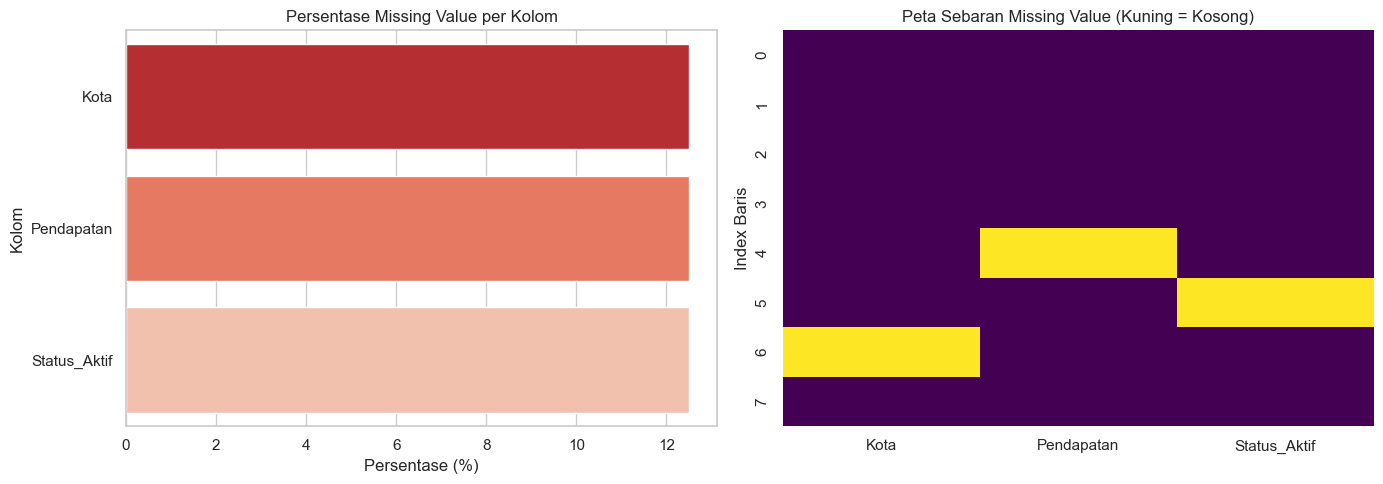

In [50]:
res_missing = analyze_missing_values(df_sample, plot=True)

Total Baris Dataset        : 8
Duplikat Persis (Full Row) : 1 baris (12.50%)

Contoh Data Duplikat (maksimal 5 baris pertama):


,ID_Pelanggan,Kota,Usia,Pendapatan,Status_Aktif
2,103,BANDUNG,28,5800.0,Tidak
3,103,BANDUNG,28,5800.0,Tidak


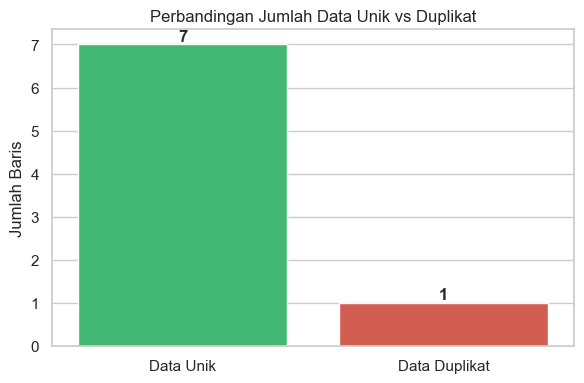

In [51]:
res_duplicates = analyze_duplicates(df_sample, plot=True)

,Batas_Bawah,Batas_Atas,Jumlah_Outlier,Persentase (%),Min_Aktual,Max_Aktual
Kolom,,,,,,
ID_Pelanggan,99.0,109.0,1,12.5,101.0,10009.0
Usia,13.0,51.0,2,25.0,-5.0,150.0
Pendapatan,4525.0,7925.0,1,12.5,5000.0,95000.0


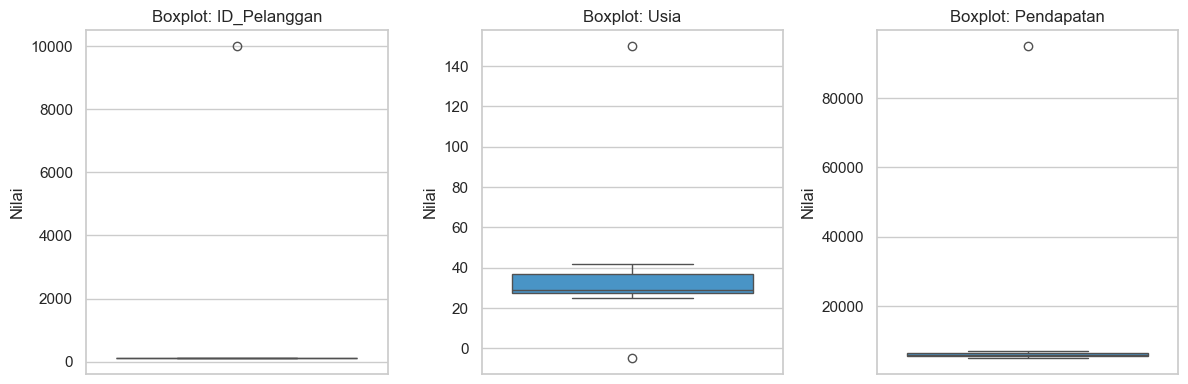

In [52]:
res_outliers = analyze_outliers(df_sample, plot=True,cat_threshold=threshold)

In [53]:
res_inconsistency = analyze_inconsistency(df_sample,cat_threshold=threshold)

Kolom 'Kota' (Tipe: object):
  [!] Masalah: Terdapat spasi berlebih di awal/akhir teks (leading/trailing space)
  [!] Masalah: Inkonsistensi huruf kapital (6 variasi vs 4 nilai unik)
  [-] Nilai unik (6): ['Jakarta', 'jakarta ', 'BANDUNG', 'Surabaya', 'surabaya', 'Medan']

Kolom 'Status_Aktif' (Tipe: object):
  [!] Masalah: Terdapat spasi berlebih di awal/akhir teks (leading/trailing space)
  [!] Masalah: Inkonsistensi huruf kapital (5 variasi vs 3 nilai unik)
  [-] Nilai unik (5): ['Ya', 'ya', 'Tidak', 'YA ', 'N/A']

Kolom Numerik 'Usia':
  [!] Ditemukan 1 nilai negatif (Min: -5). Periksa apakah valid.



In [54]:
raw_df = pd.DataFrame({
    'user_id': [101, 102, 102, 103, 104, 105, 106],
    'tgl_transaksi': ['2026-05-01', '2026-05-02', '2026-05-02', 'salah_format', '2026-05-04', '2026-05-05', '2026-05-06'],
    'umur': ['25', '30', '30', '28', '-5', '35', '150'],                 # -5 dan 150 tidak masuk akal secara konteks
    'nominal': ['Rp 150.000', 'Rp 200.000', 'Rp 200.000', None, 'Rp 180.000', 'Rp 190.000', 'Rp 9.500.000']
})
data_understanding(df=raw_df,cat_threshold=threshold)

=== 1. SHAPE & DATA TYPES ===
Jumlah Baris  : 7
Jumlah Kolom  : 4
Baris Duplikat: 1



,Dtype,Non-Null,Missing,Missing-Percentage,Unique
user_id,int64,7,0,0.00,6
tgl_transaksi,object,7,0,0.00,6
umur,object,7,0,0.00,6
nominal,object,6,1,14.29,5



=== 2. DATASET OVERVIEW (5 BARIS PERTAMA) ===


,user_id,tgl_transaksi,umur,nominal
0,101,2026-05-01,25,Rp 150.000
1,102,2026-05-02,30,Rp 200.000
2,102,2026-05-02,30,Rp 200.000
3,103,salah_format,28,None
4,104,2026-05-04,-5,Rp 180.000



=== 3. STATISTICAL SUMMARY ===
Fitur Numerik:


,count,mean,std,min,25%,50%,75%,max
user_id,7.0,103.285714,1.799471,101.0,102.0,103.0,104.5,106.0


Fitur Kategorikal / Non-Numerik:


,count,unique,top,freq
tgl_transaksi,7,6,2026-05-02,2
umur,7,6,30,2
nominal,6,5,Rp 200.000,2


In [55]:
df_clean = convert_data_types(df=raw_df,dtype_map={'umur':'int64','nominal':'float64'},date_cols=['tgl_transaksi'])


[Type Conversion] Kolom dikonversi: ['tgl_transaksi -> datetime64', 'umur -> int64', 'nominal -> float64']


In [56]:
data_understanding(df=df_clean,cat_threshold=threshold)

=== 1. SHAPE & DATA TYPES ===
Jumlah Baris  : 7
Jumlah Kolom  : 4
Baris Duplikat: 1



,Dtype,Non-Null,Missing,Missing-Percentage,Unique
user_id,int64,7,0,0.00,6
tgl_transaksi,datetime64[ns],6,1,14.29,5
umur,Int64,7,0,0.00,6
nominal,float64,5,2,28.57,4



=== 2. DATASET OVERVIEW (5 BARIS PERTAMA) ===


,user_id,tgl_transaksi,umur,nominal
0,101,2026-05-01,25,150.0
1,102,2026-05-02,30,200.0
2,102,2026-05-02,30,200.0
3,103,NaT,28,NaN
4,104,2026-05-04,-5,180.0



=== 3. STATISTICAL SUMMARY ===
Fitur Numerik:


,count,mean,std,min,25%,50%,75%,max
user_id,7.0,103.285714,1.799471,101.0,102.0,103.0,104.5,106.0
umur,7.0,41.857143,49.488815,-5.0,26.5,30.0,32.5,150.0
nominal,5.0,184.0,20.736441,150.0,180.0,190.0,200.0,200.0


Fitur Kategorikal / Non-Numerik:


,count,unique,top,freq
tgl_transaksi,6,5,2026-05-02 00:00:00,2


In [57]:
clean_missing = handle_missing_values(df=df_clean,strategy={'tgl_transaksi': 'drop', 'nominal': 'median'},cat_threshold=threshold)
clean_missing

[Missing Values]
  - tgl_transaksi: hapus 1 baris
  - nominal: imputasi median (190.00)


,user_id,tgl_transaksi,umur,nominal
0,101,2026-05-01,25,150.0
1,102,2026-05-02,30,200.0
2,102,2026-05-02,30,200.0
3,104,2026-05-04,-5,180.0
4,105,2026-05-05,35,190.0
5,106,2026-05-06,150,190.0


In [58]:
clean_duplicatet = handle_duplicates(clean_missing,subset=['user_id'])
clean_duplicatet

[Duplicate Handling] Dihapus 1 baris duplikat (Sisa: 5 baris)


,user_id,tgl_transaksi,umur,nominal
0,101,2026-05-01,25,150.0
1,102,2026-05-02,30,200.0
2,104,2026-05-04,-5,180.0
3,105,2026-05-05,35,190.0
4,106,2026-05-06,150,190.0


In [59]:
clean_outlier1 = handle_outliers(df=clean_duplicatet,cols=['umur'], action='drop', custom_bounds={'umur': (17, 90)})
clean_outlier1

[Outlier Handling] umur: 2 baris outlier dihapus


,user_id,tgl_transaksi,umur,nominal
0,101,2026-05-01,25,150.0
1,102,2026-05-02,30,200.0
2,105,2026-05-05,35,190.0


In [60]:
clean_outlier2 = handle_outliers(df=clean_outlier1,cols=['nominal'], method='iqr', action='cap', factor=1.5)
clean_outlier2

[Outlier Handling] Tidak ada outlier terdeteksi


,user_id,tgl_transaksi,umur,nominal
0,101,2026-05-01,25,150.0
1,102,2026-05-02,30,200.0
2,105,2026-05-05,35,190.0


In [61]:
clean_df = (
    raw_df
    .pipe(convert_data_types, dtype_map={'umur': 'int64', 'nominal': 'float64'}, date_cols=['tgl_transaksi'])
    .pipe(handle_duplicates, subset=['user_id'])
    .pipe(handle_missing_values, strategy={'tgl_transaksi': 'drop', 'nominal': 'median'},cat_threshold=threshold)
    .pipe(handle_outliers, cols=['umur'], action='drop', custom_bounds={'umur': (17, 90)})
    .pipe(handle_outliers, cols=['nominal'], method='iqr', action='cap', factor=1.5)
)

print("\n=== HASIL AKHIR ===")
clean_df

[Type Conversion] Kolom dikonversi: ['tgl_transaksi -> datetime64', 'umur -> int64', 'nominal -> float64']
[Duplicate Handling] Dihapus 1 baris duplikat (Sisa: 6 baris)
[Missing Values]
  - tgl_transaksi: hapus 1 baris
  - nominal: imputasi median (185.00)
[Outlier Handling] umur: 2 baris outlier dihapus
[Outlier Handling] Tidak ada outlier terdeteksi

=== HASIL AKHIR ===


,user_id,tgl_transaksi,umur,nominal
0,101,2026-05-01,25,150.0
1,102,2026-05-02,30,200.0
2,105,2026-05-05,35,190.0
